In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

# Building the pushed transfer coefficient multiindex dataframe gamma_0

Import and clean SUT like in main SUT-to-MFA_main-pipeline.ipynb

In [3]:
#load Use table of the corresponding year
year = 2019 #2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022
#Use table
file_path = f'Raw data/CA_SUT_C{year}_D.xlsx'
U_table = pd.read_excel(file_path, sheet_name='Use_Basic',index_col=0)

#clean imported Use table df for year=[2018,2019,2020,2021,2022]
U_table = U_table.reset_index(drop=True) #drop first column
U_table = U_table.drop(index=[0,1,2]) #drop all empty rows at the top
#rename row with NAICS codes accordingly
U_table.iloc[1,0] = 'Industry Code (NAICS)'


#rename duplicate industries, i.e. 'Educational services', 'Social assistance', and 'Nursing and residential care facilities' to differentiate private, non-profit, and government services and have unique industry (column) labels
#Educational services (BS610000)
mask = U_table.eq('BS610000')
row_idx, col_idx = mask.stack().idxmax()
U_table.loc[row_idx - 1, col_idx] = 'Educational services, private'
#and (NP610000)
mask = U_table.eq('NP610000')
row_idx, col_idx = mask.stack().idxmax()
U_table.loc[row_idx - 1, col_idx] = 'Educational services, non-profit'

#Social assistance (NP624000) 
mask = U_table.eq('NP624000')
row_idx, col_idx = mask.stack().idxmax()
U_table.loc[row_idx - 1, col_idx] = 'Social assistance, non-profit'
# and (BS624000)
mask = U_table.eq('BS624000')
row_idx, col_idx = mask.stack().idxmax()
U_table.loc[row_idx - 1, col_idx] = 'Social assistance, private'

#Nursing and residential care facilities (BS623000)
mask = U_table.eq('BS623000')
row_idx, col_idx = mask.stack().idxmax()
U_table.loc[row_idx - 1, col_idx] = 'Nursing and residential care facilities, private'
# and (GS623000)
mask = U_table.eq('GS623000')
row_idx, col_idx = mask.stack().idxmax()
U_table.loc[row_idx - 1, col_idx] = 'Nursing and residential care facilities, government'


#use first row as column labels
U_table.columns = U_table.iloc[0]   # use first row for column names
U_table = U_table[2:]               # remove the first two rows from the data
U_table = U_table.reset_index(drop=True)  # reset row indices

#rename fist column label 'Products' and set as index
U_table.columns.values[0] = 'Products'
U_table.index.name = None       #remove name of indices
U_table.columns.name = None     #remove name of columns
U_table.set_index('Products',inplace=True)


#drop all rows including and below 'Taxes on products' (i.e. value added section?)
bottom = U_table.index.get_loc('Taxes on products')
U_table = U_table.iloc[:bottom,:]

#replace all '.' with 0 and stay in dtype fload64
U_table = U_table.apply(pd.to_numeric, errors='coerce').fillna(0)

#U_table #(kCAD)

#scale to CAD
factor = 1000 
U_table = factor * U_table    #in CAD
U_table

,"Crop production (except cannabis, greenhouse, nursery and floriculture production)","Greenhouse, nursery and floriculture production (except cannabis)",Cannabis production (licensed),Cannabis production (unlicensed),Animal production (except aquaculture),Aquaculture,Forestry and logging,"Fishing, hunting and trapping",Support activities for crop and animal production,Support activities for forestry,...,Other federal government services (except defence),Other provincial and territorial government services,Other municipal government services,Other aboriginal government services,"Changes in inventories, finished goods and goods in process","Changes in inventories, raw materials and goods purchased for resale",International exports,International re-exports,Total use,Gross domestic product (GDP) at market prices
Products,,,,,,,,,,,,,,,,,,,,,
Canola (including rapeseed),446718000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,-95384000.0,528785000.0,3.394783e+09,197000.0,8.887360e+09,0.0
Oilseeds (except canola),206214000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,-135803000.0,247448000.0,1.725457e+09,17375000.0,3.138673e+09,0.0
Wheat,240689000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,10595000.0,650920000.0,4.765246e+09,20012000.0,6.971869e+09,0.0
Grains (except wheat),404156000.0,0.0,0.0,0.0,418306000.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,155975000.0,83379000.0,1.144384e+09,5481000.0,5.414948e+09,0.0
Fresh potatoes,9362000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,45252000.0,-7222000.0,2.862840e+08,62000.0,1.484093e+09,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Defence services,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,2.164258e+10,0.0
Other federal government services,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,5.373404e+10,0.0
Other provincial and territorial government services,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,1.208502e+11,0.0


In [4]:
#separate Use table into Use matrix U and Final demand Y
#Final demand matrix (CAD)
Y = U_table.loc[:,'Food':'International re-exports']
Y = Y.fillna(0)

#Use matrix U (CAD)
#drop all columns including and right of 'Total' (i.e. the final demand section)
pos = U_table.columns.get_loc('Total')
U = U_table.iloc[:,:pos]
U = U.fillna(0)

U #in CAD

,"Crop production (except cannabis, greenhouse, nursery and floriculture production)","Greenhouse, nursery and floriculture production (except cannabis)",Cannabis production (licensed),Cannabis production (unlicensed),Animal production (except aquaculture),Aquaculture,Forestry and logging,"Fishing, hunting and trapping",Support activities for crop and animal production,Support activities for forestry,...,Community colleges and C.E.G.E.P.s,Universities,Other educational services,Hospitals,"Nursing and residential care facilities, government",Defence services,Other federal government services (except defence),Other provincial and territorial government services,Other municipal government services,Other aboriginal government services
Products,,,,,,,,,,,,,,,,,,,,,
Canola (including rapeseed),446718000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Oilseeds (except canola),206214000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Wheat,240689000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Grains (except wheat),404156000.0,0.0,0.0,0.0,418306000.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Fresh potatoes,9362000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Defence services,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Other federal government services,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Other provincial and territorial government services,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
#Supply table
V_table = pd.read_excel(file_path, sheet_name='Supply',index_col=0)

#clean imported Supply table df for year=[2018,2019,2020,2021,2022]
V_table = V_table.reset_index(drop=True) #drop first column
V_table = V_table.drop(index=[0,1,2]) #drop all empty rows at the top


#rename duplicate industries, i.e. 'Educational services', 'Social assistance', and 'Nursing and residential care facilities' to differentiate private, non-profit, and government services and have unique industry (column) labels
#Educational services (BS610000)
mask = V_table.eq('BS610000')
row_idx, col_idx = mask.stack().idxmax()
V_table.loc[row_idx - 1, col_idx] = 'Educational services, private'
#and (NP610000)
mask = V_table.eq('NP610000')
row_idx, col_idx = mask.stack().idxmax()
V_table.loc[row_idx - 1, col_idx] = 'Educational services, non-profit'

#Social assistance (NP624000) 
mask = V_table.eq('NP624000')
row_idx, col_idx = mask.stack().idxmax()
V_table.loc[row_idx - 1, col_idx] = 'Social assistance, non-profit'
# and (BS624000)
mask = V_table.eq('BS624000')
row_idx, col_idx = mask.stack().idxmax()
V_table.loc[row_idx - 1, col_idx] = 'Social assistance, private'

#Nursing and residential care facilities (BS623000)
mask = V_table.eq('BS623000')
row_idx, col_idx = mask.stack().idxmax()
V_table.loc[row_idx - 1, col_idx] = 'Nursing and residential care facilities, private'
# and (GS623000)
mask = V_table.eq('GS623000')
row_idx, col_idx = mask.stack().idxmax()
V_table.loc[row_idx - 1, col_idx] = 'Nursing and residential care facilities, government'



#use first row as column labels
V_table.columns = V_table.iloc[0]   # use first row for column names
V_table = V_table[2:]               # remove the first two rows from the data
V_table = V_table.reset_index(drop=True)  # reset row indices

#rename fist column label 'Products' and set as index
V_table.index.name = None #remove name of indices
V_table.columns.name = None   #remove name of columns
V_table.rename(columns={'Industries': 'Products'}, inplace=True)
V_table.set_index('Products',inplace=True)

#drop all columns including and right of 'Total' (i.e. the imports section)
#pos = V_table.columns.get_loc('Total')
#V_table = V_table.iloc[:,:pos]

#drop all rows including and below 'Taxes on products' (i.e. value added section?)
bottom = V_table.index.get_loc('Taxes on products')
V_table = V_table.iloc[:bottom,:]

#replace all '.' with 0 and stay in dtype fload64
V_table = V_table.apply(pd.to_numeric, errors='coerce').fillna(0)

#V_table #(kCAD)

V_table = factor * V_table  
V_table #in CAD

,"Crop production (except cannabis, greenhouse, nursery and floriculture production)","Greenhouse, nursery and floriculture production (except cannabis)",Cannabis production (licensed),Cannabis production (unlicensed),Animal production (except aquaculture),Aquaculture,Forestry and logging,"Fishing, hunting and trapping",Support activities for crop and animal production,Support activities for forestry,...,Other provincial and territorial government services,Other municipal government services,Other aboriginal government services,Total,International imports,Total supply at basic prices,Trade margins,"Transportation, gas and storage margins",Taxes on products,Total supply at purchasers' prices
Products,,,,,,,,,,,,,,,,,,,,,
Canola (including rapeseed),8.517984e+09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000e+00,0.000000e+00,0.000000e+00,8.773680e+09,113680000.0,8.887360e+09,6.998710e+08,7.402830e+08,8912000.0,1.033643e+10
Oilseeds (except canola),2.613263e+09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000e+00,0.000000e+00,0.000000e+00,2.718903e+09,419770000.0,3.138673e+09,4.559860e+08,4.478510e+08,6000.0,4.042516e+09
Wheat,6.914780e+09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000e+00,0.000000e+00,0.000000e+00,6.917027e+09,54842000.0,6.971869e+09,1.191471e+09,1.832528e+09,0.0,9.995868e+09
Grains (except wheat),4.621818e+09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000e+00,0.000000e+00,0.000000e+00,4.626343e+09,788605000.0,5.414948e+09,6.183110e+08,9.130610e+08,0.0,6.946320e+09
Fresh potatoes,1.329938e+09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000e+00,0.000000e+00,0.000000e+00,1.329938e+09,154155000.0,1.484093e+09,6.699740e+08,8.351300e+07,130000.0,2.237710e+09
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Defence services,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000e+00,0.000000e+00,0.000000e+00,2.164258e+10,0.0,2.164258e+10,0.000000e+00,0.000000e+00,0.0,2.164258e+10
Other federal government services,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000e+00,0.000000e+00,0.000000e+00,5.373404e+10,0.0,5.373404e+10,0.000000e+00,0.000000e+00,0.0,5.373404e+10
Other provincial and territorial government services,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.208502e+11,0.000000e+00,0.000000e+00,1.208502e+11,0.0,1.208502e+11,0.000000e+00,0.000000e+00,0.0,1.208502e+11


In [6]:
#separate V table into Supply matrix V and import vector v_imp
#Import vector v_imp (CAD)
v_imp = V_table[['International imports']]
v_imp = v_imp.fillna(0)

#Supply matrix V (CAD)
#drop all columns including and right of 'Total' (i.e. the imports section)
pos = V_table.columns.get_loc('Total')
V = V_table.iloc[:,:pos]

V #CAD

,"Crop production (except cannabis, greenhouse, nursery and floriculture production)","Greenhouse, nursery and floriculture production (except cannabis)",Cannabis production (licensed),Cannabis production (unlicensed),Animal production (except aquaculture),Aquaculture,Forestry and logging,"Fishing, hunting and trapping",Support activities for crop and animal production,Support activities for forestry,...,Community colleges and C.E.G.E.P.s,Universities,Other educational services,Hospitals,"Nursing and residential care facilities, government",Defence services,Other federal government services (except defence),Other provincial and territorial government services,Other municipal government services,Other aboriginal government services
Products,,,,,,,,,,,,,,,,,,,,,
Canola (including rapeseed),8.517984e+09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
Oilseeds (except canola),2.613263e+09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
Wheat,6.914780e+09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
Grains (except wheat),4.621818e+09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
Fresh potatoes,1.329938e+09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Defence services,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2.164258e+10,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
Other federal government services,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000e+00,5.373404e+10,0.000000e+00,0.000000e+00,0.000000e+00
Other provincial and territorial government services,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00,1.208502e+11,0.000000e+00,0.000000e+00


## Build Gamma (push transfer) multiindex dataframe

In [7]:
# U          -> 2D dataframe (only .columns and .index are used)
# col_labels -> list of environmental extension (factors) column labels for the new dataframe
col_labels = ['Waste','Capital formation','Environment']

gamma_init = pd.MultiIndex.from_product(
    [U.columns, U.index],names=['Industries', 'Products'])  # set names for labeled indices

gamma = pd.DataFrame(0.0,index=gamma_init,columns=col_labels)

gamma

Waste  \
Industries                                         Products                                                    
Crop production (except cannabis, greenhouse, n... Canola (including rapeseed)                           0.0   
                                                   Oilseeds (except canola)                              0.0   
                                                   Wheat                                                 0.0   
                                                   Grains (except wheat)                                 0.0   
                                                   Fresh potatoes                                        0.0   
...                                                                                                      ...   
Other aboriginal government services               Defence services                                      0.0   
                                                   Other federal government services                     0.0   
                                                   Other provincial and territorial government ser...    0.0   
                                                   Other municipal government services                   0.0   
                                                   Other aboriginal government services                  0.0   

                                                                                                       Capital formation  \
Industries                                         Products                                                                
Crop production (except cannabis, greenhouse, n... Canola (including rapeseed)                                       0.0   
                                                   Oilseeds (except canola)                                          0.0   
                                                   Wheat                                                             0.0   
                                                   Grains (except wheat)                                             0.0   
                                                   Fresh potatoes                                                    0.0   
...                                                                                                                  ...   
Other aboriginal government services               Defence services                                                  0.0   
                                                   Other federal government services                                 0.0   
                                                   Other provincial and territorial government ser...                0.0   
                                                   Other municipal government services                               0.0   
                                                   Other aboriginal government services                              0.0   

                                                                                                       Environment  
Industries                                         Products                                                         
Crop production (except cannabis, greenhouse, n... Canola (including rapeseed)                                 0.0  
                                                   Oilseeds (except canola)                                    0.0  
                                                   Wheat                                                       0.0  
                                                   Grains (except wheat)                                       0.0  
                                                   Fresh potatoes                                              0.0  
...                                                                                                            ...  
Other aboriginal government services               Defence services                              

# Step 0: Remove packaging products from gamma tree

Split U into U_packaging and U

In [8]:
#import packaging mapping matrix
filter_pack = pd.read_excel('SI2_mapping_tables.xlsx',sheet_name='filter_packaging_binary',index_col=0)
filter_pack = filter_pack.fillna(0)

In [9]:
#multiply the U matrix and filter_pack elementwise
U_pack = U * filter_pack

#subtract U_pack from U for the following operations 
#next use for U_pack is after the optimisation converting it to mass with the alpha_prime found based on U in the optimisation
U = U - U_pack
U

,"Crop production (except cannabis, greenhouse, nursery and floriculture production)","Greenhouse, nursery and floriculture production (except cannabis)",Cannabis production (licensed),Cannabis production (unlicensed),Animal production (except aquaculture),Aquaculture,Forestry and logging,"Fishing, hunting and trapping",Support activities for crop and animal production,Support activities for forestry,...,Community colleges and C.E.G.E.P.s,Universities,Other educational services,Hospitals,"Nursing and residential care facilities, government",Defence services,Other federal government services (except defence),Other provincial and territorial government services,Other municipal government services,Other aboriginal government services
Products,,,,,,,,,,,,,,,,,,,,,
Canola (including rapeseed),446718000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Oilseeds (except canola),206214000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Wheat,240689000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Grains (except wheat),404156000.0,0.0,0.0,0.0,418306000.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Fresh potatoes,9362000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Defence services,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Other federal government services,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Other provincial and territorial government services,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Step 1: Define plastic-containing products based on alpha_0
Question: Does product i contain plastic?

In [10]:
#import alpha_0 to determine which products need transfer coefficients and which don't
alpha_0 = pd.read_excel('SI2_mapping_tables.xlsx',sheet_name='Alpha_0_Claude',index_col=0)

#put in template only products that contain plastic
alpha_0_template = alpha_0.loc[(alpha_0 != 0).any(axis=1)].copy()

#create a binary alpha_0 (1 = value, 0 = 0)
alpha_0_binary = alpha_0.copy()
alpha_0_binary[alpha_0_binary != 0] = 1

alpha_0_binary

,Plastic intensity
Products,
Canola (including rapeseed),0.0
Oilseeds (except canola),0.0
Wheat,0.0
Grains (except wheat),0.0
Fresh potatoes,0.0
...,...
Defence services,0.0
Other federal government services,0.0
Other provincial and territorial government services,0.0


## Step 2: Define single values based on external data
Question: Is there industry J and/or product i-specific data available?

In [11]:
#setting industry-specific TC
#import summary sheet of Gamma_custom_data
custom_g = pd.read_excel('SI2_mapping_tables.xlsx',sheet_name='custom-TCs',index_col=0)
custom_g

,Products,Gamma Waste,Gamma Capital formation,Gamma Environment,Reference
Industries,,,,,
Plastic product manufacturing,Plastic resins,0.028,0.0,0.000,mean of all processing methods ecoinvent versi...
"Fishing, hunting and trapping",all products,NaN,NaN,0.147,"mean of all fishing devices Richardson, K., Ha..."


In [55]:
#apply the values at the end

## Step 3: Define degrees of fabrication relative to what products k are supplied by industry J
Question: Can product i be embedded in or accompany products k supplied by industry J? Following the "Degrees of fabrication" approach by Nakamura et al. (2007).


<Axes: ylabel='Products'>

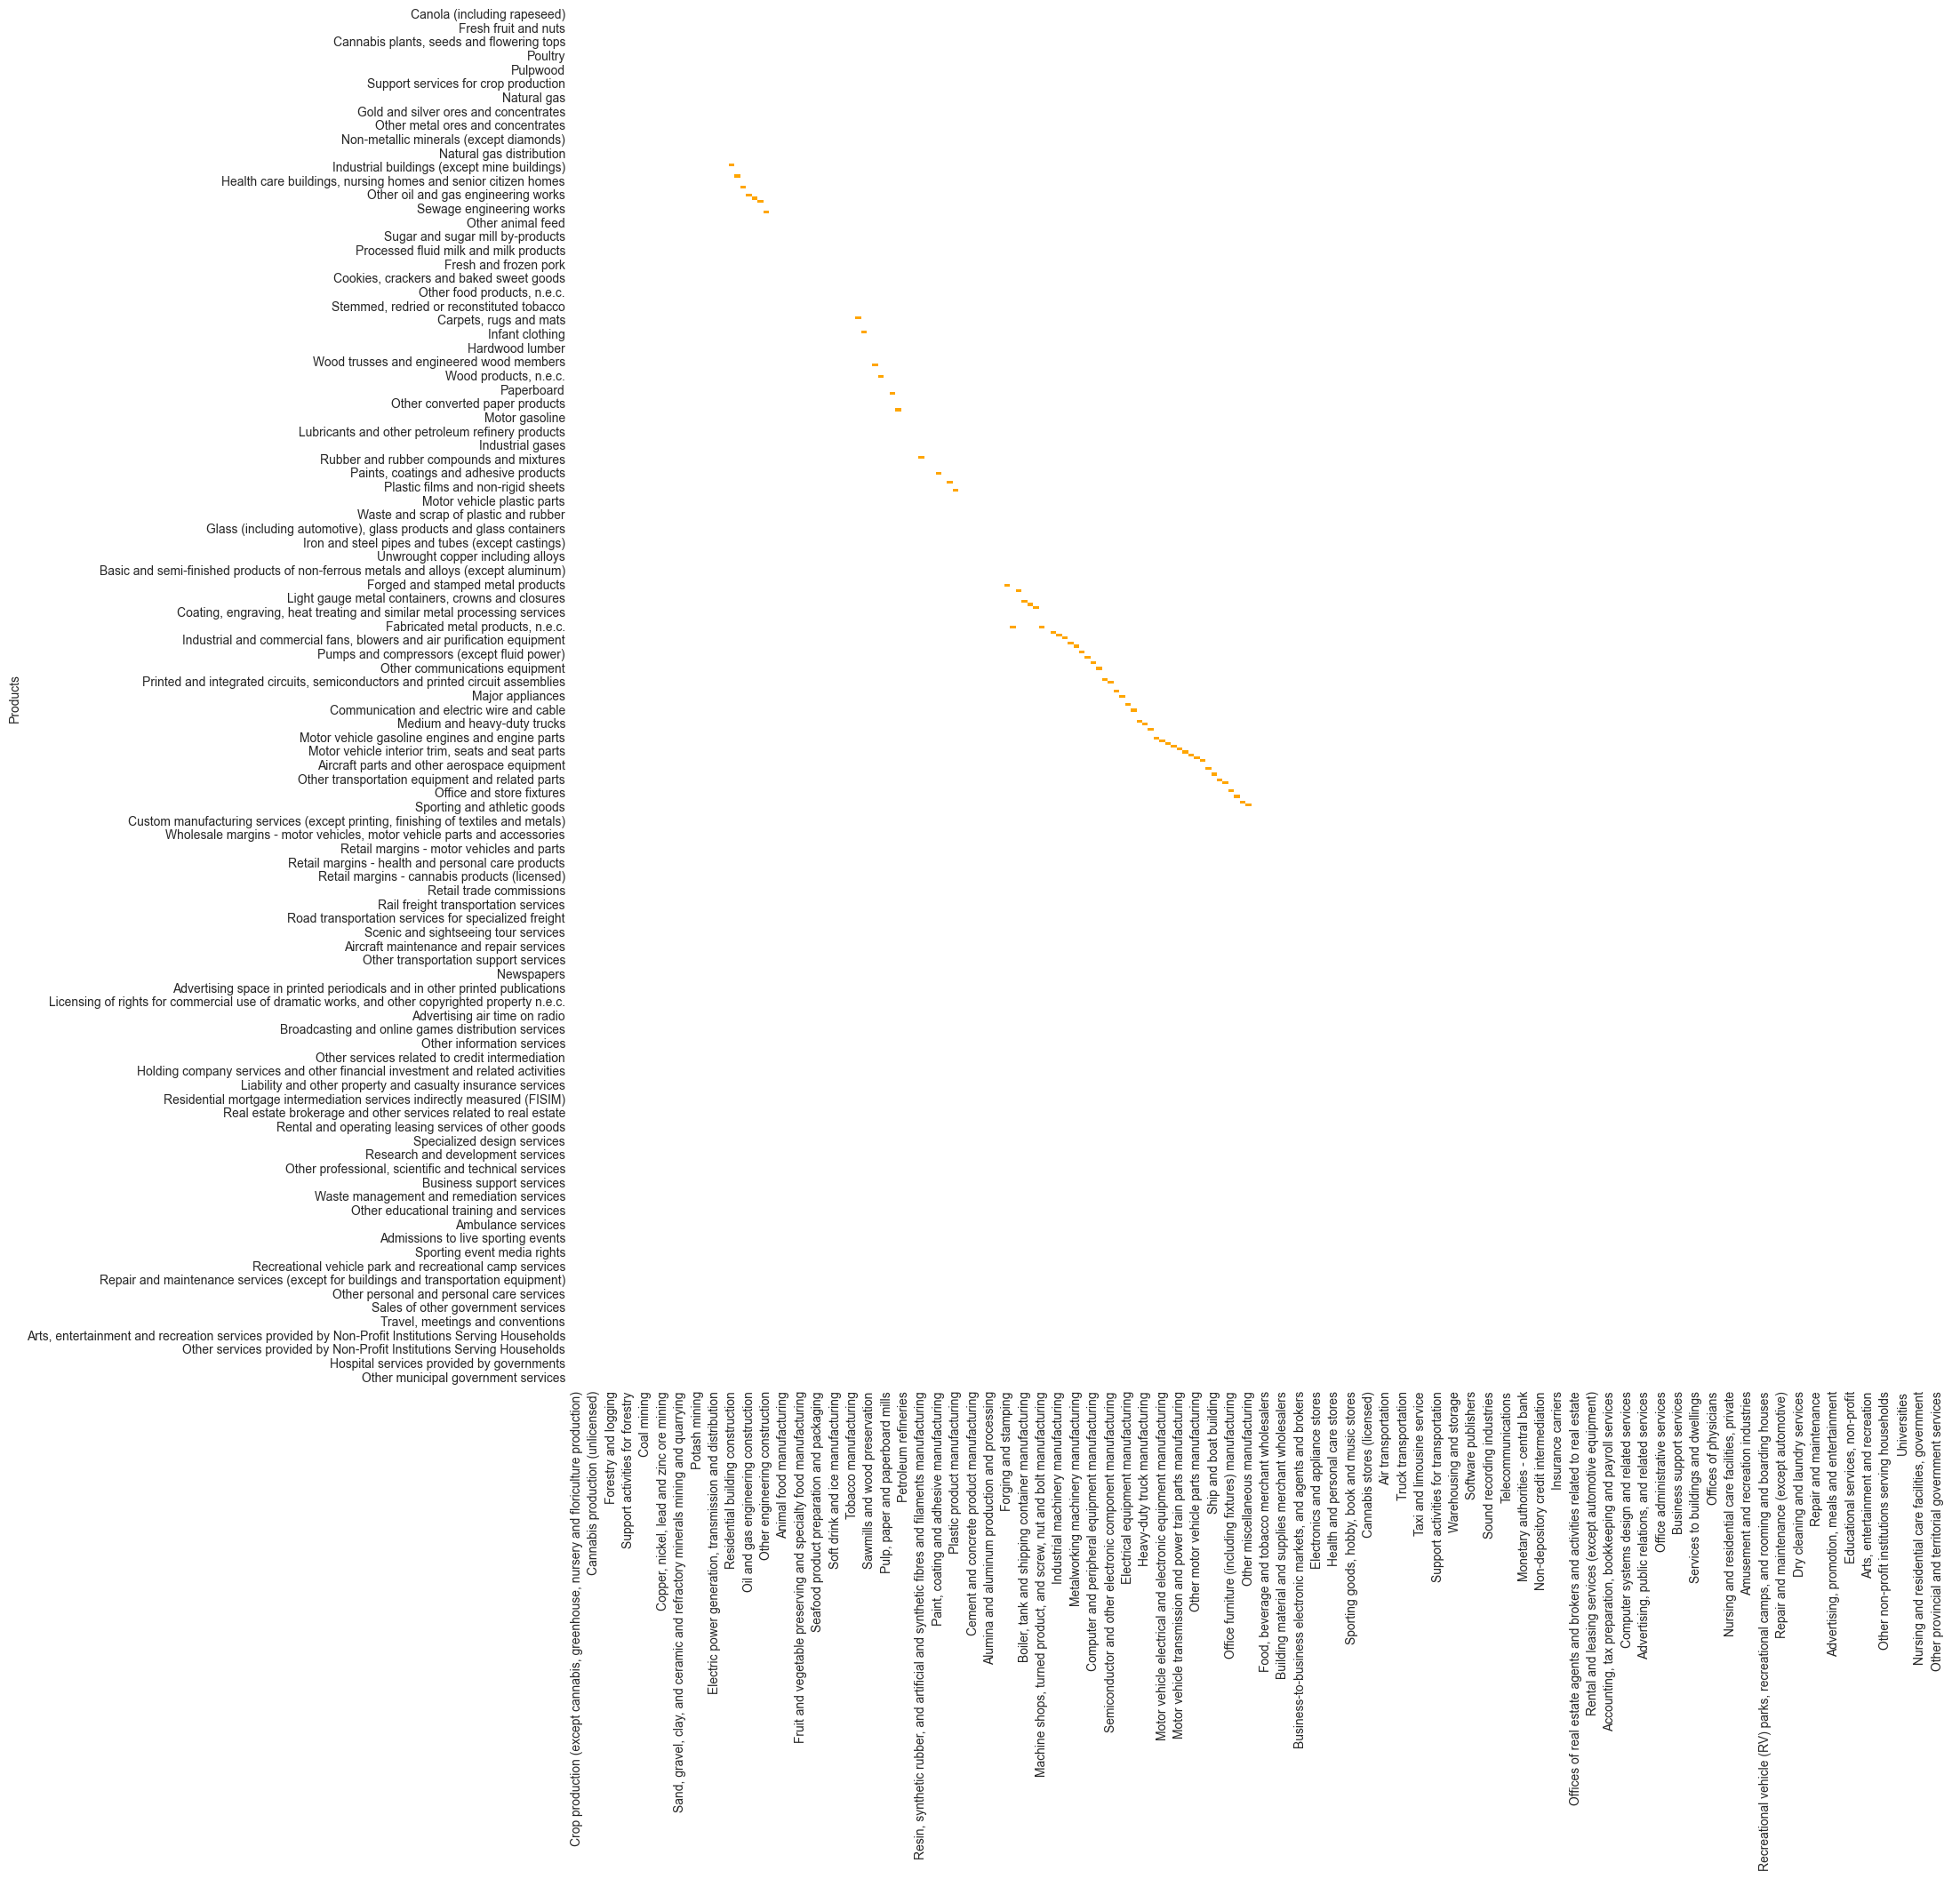

In [12]:
#create heatmap of main products in V filtered for only plastic-containing products
V_main = V.copy()

#show only the main product (one product per industry with the largest supply)
V_main = V_main.where(V_main.eq(V_main.max()), 0)

#show only main, plastic-containing products
V_main_plastic = V_main.mul(alpha_0['Plastic intensity'], axis=0)
V_main_plastic = V_main_plastic.fillna(0)

#Defining heatmap
colors = ['white', 'orange']  #0,1
cmap = ListedColormap(colors)

#define the discrete boundaries between values
bounds = [-1, 0.5, 1e12]
norm = BoundaryNorm(bounds, cmap.N)

#define size of heatmap
fig, ax = plt.subplots(figsize=(20, 20))
#plot
sns.heatmap(V_main_plastic, cmap=cmap, norm=norm, cbar=False, label='orange = plastic-containing supply')

In [13]:
V_main_plastic

,"Crop production (except cannabis, greenhouse, nursery and floriculture production)","Greenhouse, nursery and floriculture production (except cannabis)",Cannabis production (licensed),Cannabis production (unlicensed),Animal production (except aquaculture),Aquaculture,Forestry and logging,"Fishing, hunting and trapping",Support activities for crop and animal production,Support activities for forestry,...,Community colleges and C.E.G.E.P.s,Universities,Other educational services,Hospitals,"Nursing and residential care facilities, government",Defence services,Other federal government services (except defence),Other provincial and territorial government services,Other municipal government services,Other aboriginal government services
Products,,,,,,,,,,,,,,,,,,,,,
Canola (including rapeseed),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Oilseeds (except canola),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Wheat,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Grains (except wheat),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Fresh potatoes,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Defence services,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Other federal government services,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Other provincial and territorial government services,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [14]:
#turn it into a dictionary
V_main_plastic_dict = V_main_plastic.ne(0).idxmax().where(V_main_plastic.ne(0).any(), 'No main product').to_dict()
V_main_plastic_dict

{'Crop production (except cannabis, greenhouse, nursery and floriculture production)': 'No main product',
 'Greenhouse, nursery and floriculture production (except cannabis)': 'No main product',
 'Cannabis production (licensed)': 'No main product',
 'Cannabis production (unlicensed)': 'No main product',
 'Animal production (except aquaculture)': 'No main product',
 'Aquaculture': 'No main product',
 'Forestry and logging': 'No main product',
 'Fishing, hunting and trapping': 'No main product',
 'Support activities for crop and animal production': 'No main product',
 'Support activities for forestry': 'No main product',
 'Oil and gas extraction (except oil sands)': 'No main product',
 'Oil sands extraction': 'No main product',
 'Coal mining': 'No main product',
 'Iron ore mining': 'No main product',
 'Gold and silver ore mining': 'No main product',
 'Copper, nickel, lead and zinc ore mining': 'No main product',
 'Other metal ore mining': 'No main product',
 'Stone mining and quarrying':

In [15]:
#import filter vector for final products and new product order
filter_finals = pd.read_excel('SI2_mapping_tables.xlsx', sheet_name='degree of fab_new order',index_col=0)[['Final products']].fillna(0)
filter_finals

,Final products
Products,
Plastic resins,0.0
Artificial and synthetic fibres and filaments,0.0
"Paints, coatings and adhesive products",0.0
"Chemical products, n.e.c.",0.0
Plastic bags,0.0
...,...
Defence services,0.0
Other federal government services,0.0
Other provincial and territorial government services,0.0


In [16]:
#for each industry define which products have a lower (can be embedded) and higher degree of fabrication than the main plastic-containing product supplied V_main_plastic_dict
# SUT metrix structure in the product order of filter_finals
deg_fab = pd.DataFrame(0, index=filter_finals.index, columns=V.columns) 


#-1 for lower or equal degree of fabrication, i.e. lower index, 
# 1 for higher degree of fabrication, infrastructure received a 1 per definition (cannot be embedded in any product), i.e. higher index

positions = np.arange(len(deg_fab.index))            # 0, 1, 2, ... for each row
target_pos = np.full(len(deg_fab.columns), -1)       # will hold mapped index position per column
no_main = np.zeros(len(deg_fab.columns), dtype=bool) # flags columns with 'No main product'

for i, col in enumerate(deg_fab.columns):
    val = V_main_plastic_dict[col]
    if val == 'No main product':
        no_main[i] = True
    else:
        target_pos[i] = deg_fab.index.get_loc(val)

# broadcast comparison: rows (axis 0) vs columns' target position (axis 1)
#-1 for lower or equal degree of fabrication, 
# 1 for higher degree of fabrication
result = np.where(positions[:, None] <= target_pos[None, :], -1,1)
result[:, no_main] = 1   # override columns with no main product: all 1

#finals received a 1 per definition (cannot be embedded in any product)
filter_finals_series = filter_finals.iloc[:, 0]
filter_finals_aligned = filter_finals_series.reindex(deg_fab.index) #should not be necessary but do it anyway
row_override = (filter_finals_aligned == 1).to_numpy()
result[row_override, :] = 1


deg_fab = pd.DataFrame(result, index=deg_fab.index, columns=deg_fab.columns)

#set deg_fab to 0 for all non-plastic containing products
#bring deg_fab's index back to the regular SUT order
sorted_index = alpha_0_binary.index
#sort all three dataframes to match
deg_fab = deg_fab.loc[sorted_index]
deg_fab = deg_fab.mul(alpha_0_binary['Plastic intensity'], axis=0)

deg_fab

,"Crop production (except cannabis, greenhouse, nursery and floriculture production)","Greenhouse, nursery and floriculture production (except cannabis)",Cannabis production (licensed),Cannabis production (unlicensed),Animal production (except aquaculture),Aquaculture,Forestry and logging,"Fishing, hunting and trapping",Support activities for crop and animal production,Support activities for forestry,...,Community colleges and C.E.G.E.P.s,Universities,Other educational services,Hospitals,"Nursing and residential care facilities, government",Defence services,Other federal government services (except defence),Other provincial and territorial government services,Other municipal government services,Other aboriginal government services
Products,,,,,,,,,,,,,,,,,,,,,
Canola (including rapeseed),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Oilseeds (except canola),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Wheat,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Grains (except wheat),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Fresh potatoes,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Defence services,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Other federal government services,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Other provincial and territorial government services,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


<Axes: ylabel='Products'>

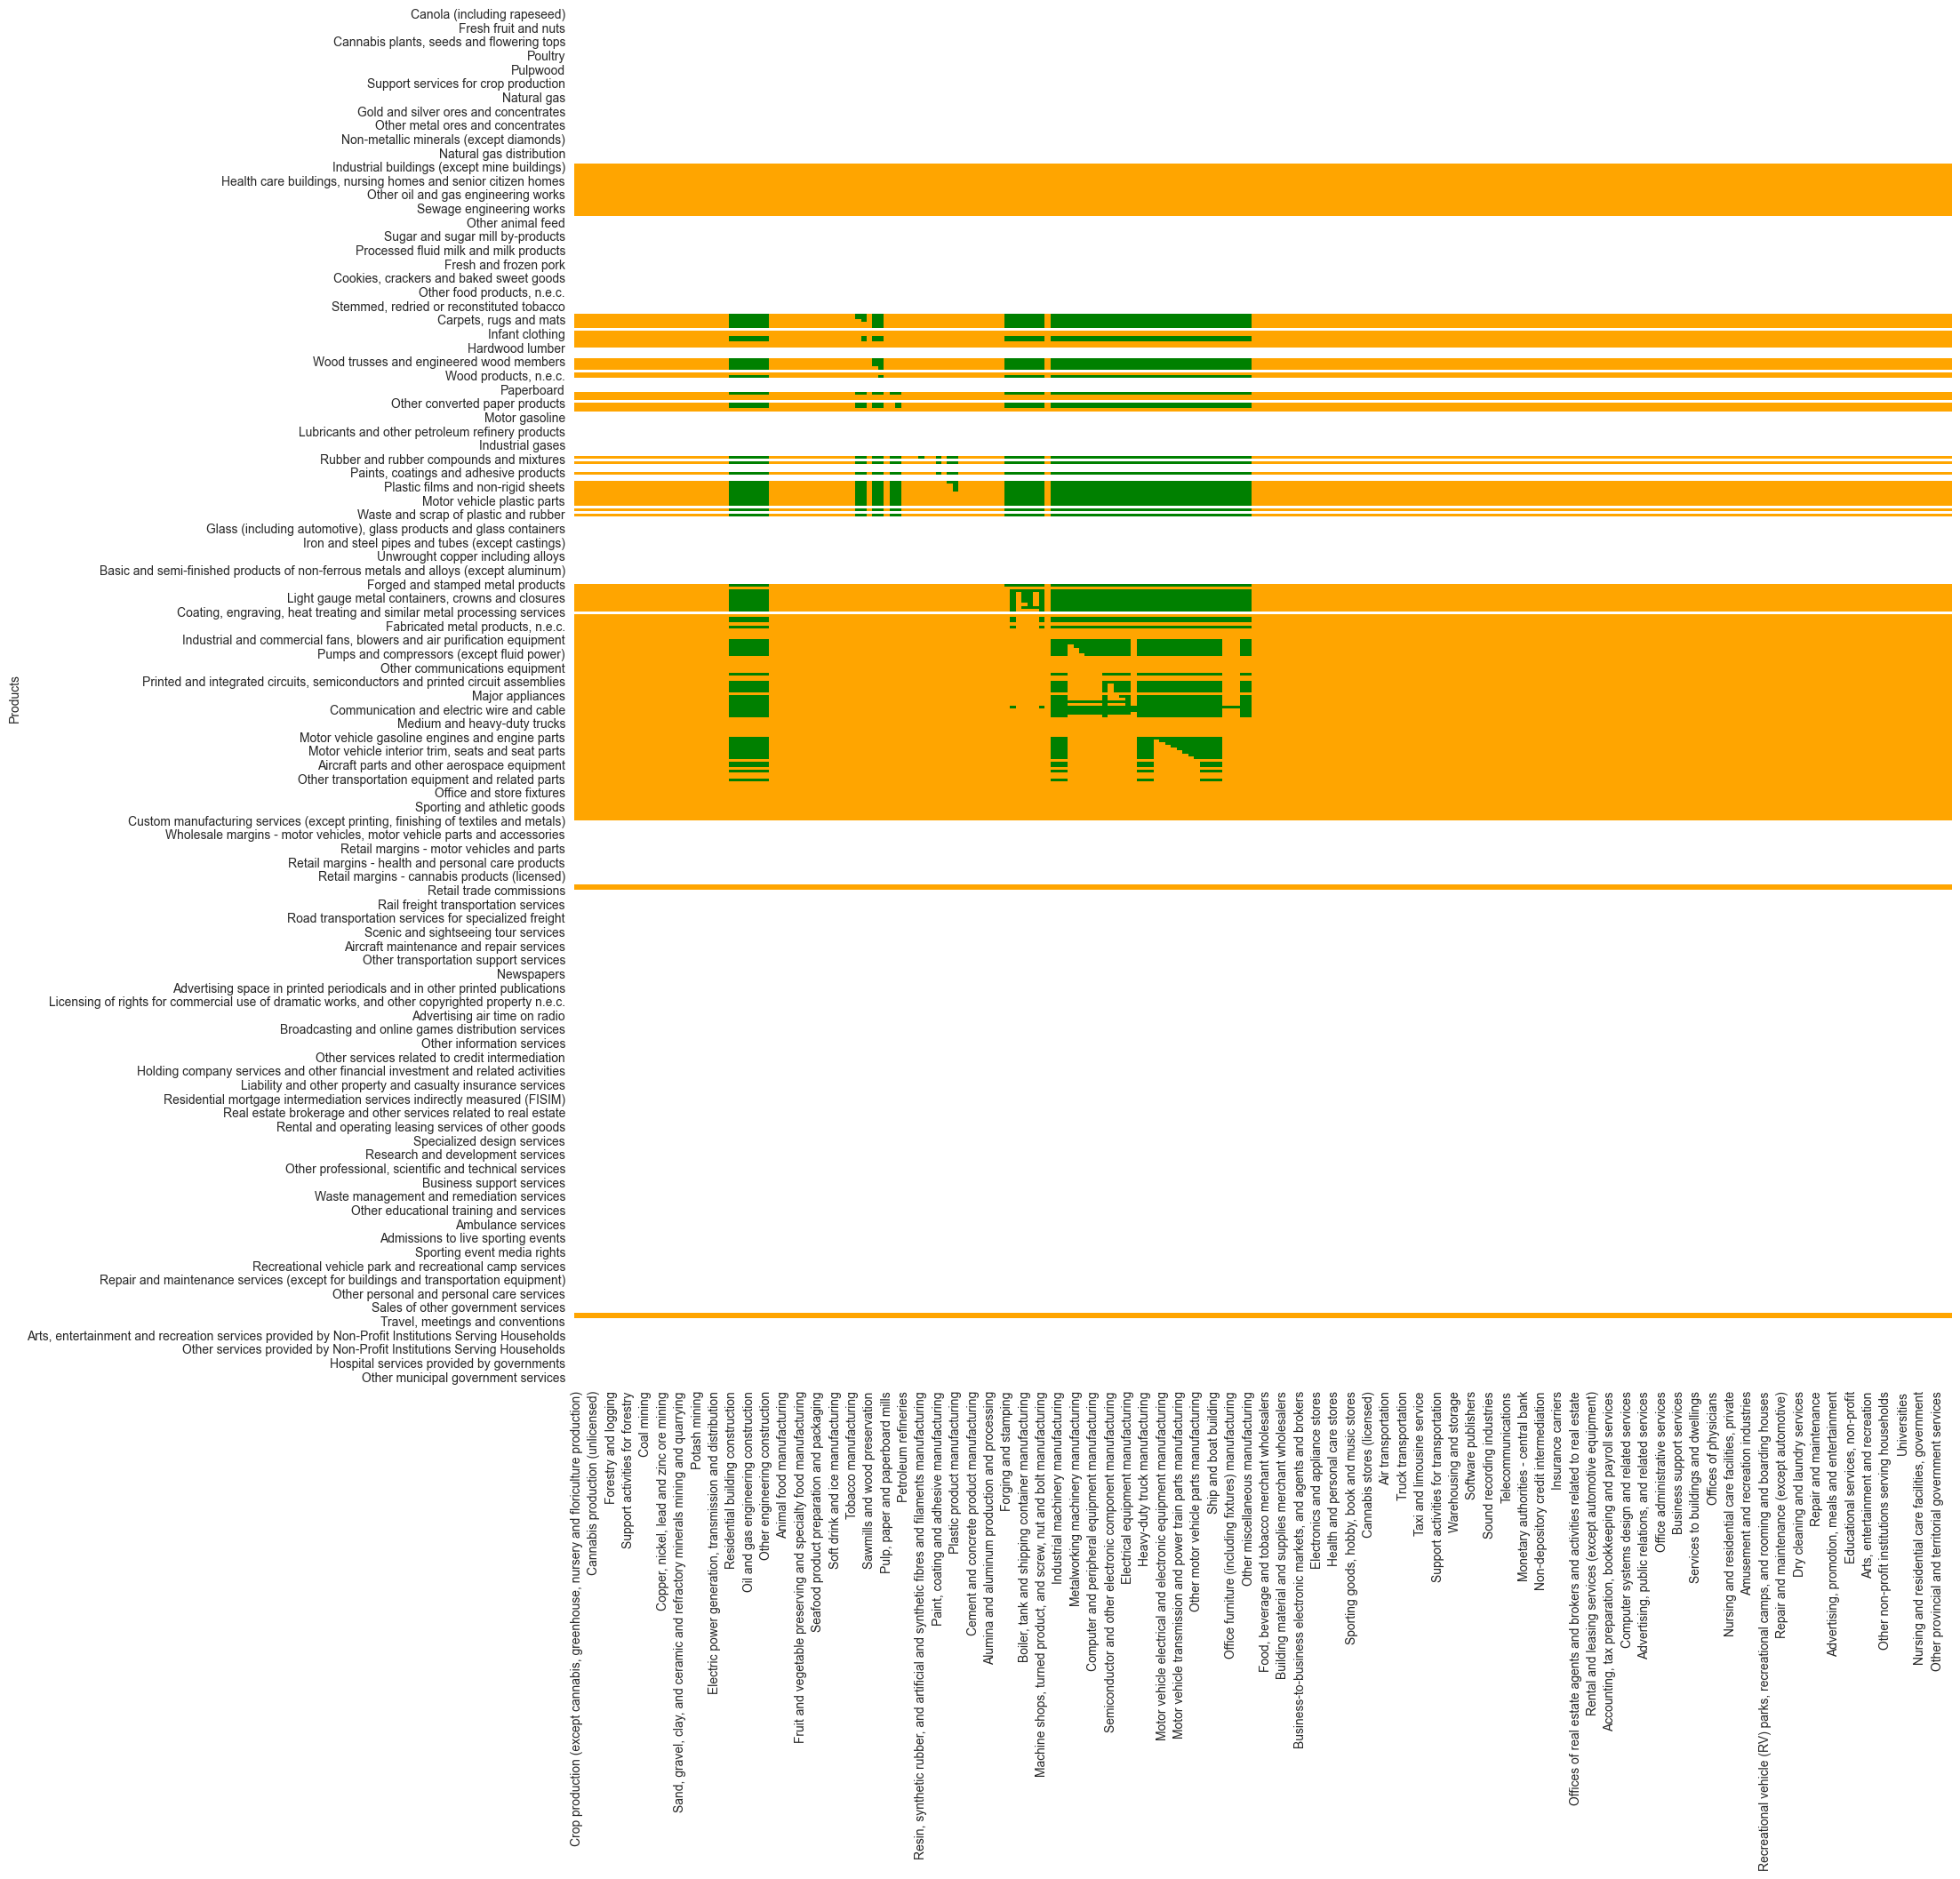

In [17]:
#heatmap
colors = ['green','white', 'orange']  #-1,0,1
cmap = ListedColormap(colors)

#define the discrete boundaries between values
bounds = [-5,-0.5, 0.5, 1e12]
norm = BoundaryNorm(bounds, cmap.N)

#define size of heatmap
fig, ax = plt.subplots(figsize=(20, 20))

#plot
sns.heatmap(deg_fab, cmap=cmap, norm=norm, cbar=False)

## Step 4: Define durability of products
Question: Is i a durable product?

In [18]:
#non-durable = 1, else/durable = 0
filter_non_dur = pd.read_excel('SI2_mapping_tables.xlsx',sheet_name='filter_non-durable',index_col=0)
#making sure it is only plastic-containing products
filter_non_dur = filter_non_dur.mul(alpha_0_binary['Plastic intensity'], axis=0).fillna(0)

#assign TC(CP) = 1 to products that are durable and have a higher degree of fabrication (step 3) than the supplied products 
for ind in deg_fab.columns:
    for prod in deg_fab.index:
        if deg_fab.loc[prod,ind] == 1 and filter_non_dur.loc[prod,'non-durable'] == 0:
            gamma.loc[(ind, prod),'Capital formation'] = 1
            
gamma

Waste  \
Industries                                         Products                                                    
Crop production (except cannabis, greenhouse, n... Canola (including rapeseed)                           0.0   
                                                   Oilseeds (except canola)                              0.0   
                                                   Wheat                                                 0.0   
                                                   Grains (except wheat)                                 0.0   
                                                   Fresh potatoes                                        0.0   
...                                                                                                      ...   
Other aboriginal government services               Defence services                                      0.0   
                                                   Other federal government services                     0.0   
                                                   Other provincial and territorial government ser...    0.0   
                                                   Other municipal government services                   0.0   
                                                   Other aboriginal government services                  0.0   

                                                                                                       Capital formation  \
Industries                                         Products                                                                
Crop production (except cannabis, greenhouse, n... Canola (including rapeseed)                                       0.0   
                                                   Oilseeds (except canola)                                          0.0   
                                                   Wheat                                                             0.0   
                                                   Grains (except wheat)                                             0.0   
                                                   Fresh potatoes                                                    0.0   
...                                                                                                                  ...   
Other aboriginal government services               Defence services                                                  0.0   
                                                   Other federal government services                                 0.0   
                                                   Other provincial and territorial government ser...                0.0   
                                                   Other municipal government services                               0.0   
                                                   Other aboriginal government services                              0.0   

                                                                                                       Environment  
Industries                                         Products                                                         
Crop production (except cannabis, greenhouse, n... Canola (including rapeseed)                                 0.0  
                                                   Oilseeds (except canola)                                    0.0  
                                                   Wheat                                                       0.0  
                                                   Grains (except wheat)                                       0.0  
                                                   Fresh potatoes                                              0.0  
...                                                                                                            ...  
Other aboriginal government services               Defence services                              

## Step 5: Define emissions into the environment
Question: Are industry J's activities mainly taking place outdoors?

For products with a higher degree of fabrication

In [19]:
#defined a list of industries with outdoor activities
#Industry archetypes: Agriculture, Mining, Construction, Waste management, Services (in parts)
outdoor_ind = pd.read_excel('SI2_mapping_tables.xlsx',sheet_name='filter_outdoor-activities',index_col=0)
outdoor_ind_short = outdoor_ind[outdoor_ind['Outdoor activities'] == 1]

#according to OECD (2022) about 0.7% of the global primary plastic production is emitted into the environment before the use phase
env_factor = 0.007

for ind in outdoor_ind_short.index:
    for prod in deg_fab.index:
        #if higher degree of fabrication and non-durable product
        if deg_fab.loc[prod,ind] == 1 and filter_non_dur.loc[prod,'non-durable'] == 1: 
            gamma.loc[(ind, prod),'Environment'] = env_factor
            gamma.loc[(ind, prod),'Waste'] = 1 - env_factor

gamma

Waste  \
Industries                                         Products                                                    
Crop production (except cannabis, greenhouse, n... Canola (including rapeseed)                           0.0   
                                                   Oilseeds (except canola)                              0.0   
                                                   Wheat                                                 0.0   
                                                   Grains (except wheat)                                 0.0   
                                                   Fresh potatoes                                        0.0   
...                                                                                                      ...   
Other aboriginal government services               Defence services                                      0.0   
                                                   Other federal government services                     0.0   
                                                   Other provincial and territorial government ser...    0.0   
                                                   Other municipal government services                   0.0   
                                                   Other aboriginal government services                  0.0   

                                                                                                       Capital formation  \
Industries                                         Products                                                                
Crop production (except cannabis, greenhouse, n... Canola (including rapeseed)                                       0.0   
                                                   Oilseeds (except canola)                                          0.0   
                                                   Wheat                                                             0.0   
                                                   Grains (except wheat)                                             0.0   
                                                   Fresh potatoes                                                    0.0   
...                                                                                                                  ...   
Other aboriginal government services               Defence services                                                  0.0   
                                                   Other federal government services                                 0.0   
                                                   Other provincial and territorial government ser...                0.0   
                                                   Other municipal government services                               0.0   
                                                   Other aboriginal government services                              0.0   

                                                                                                       Environment  
Industries                                         Products                                                         
Crop production (except cannabis, greenhouse, n... Canola (including rapeseed)                                 0.0  
                                                   Oilseeds (except canola)                                    0.0  
                                                   Wheat                                                       0.0  
                                                   Grains (except wheat)                                       0.0  
                                                   Fresh potatoes                                              0.0  
...                                                                                                            ...  
Other aboriginal government services               Defence services                              

In [20]:
#adding waste TCs for all non-durable plastic-containing products that are used by industries without outdoor activities
indoor_ind_short = outdoor_ind[outdoor_ind['Outdoor activities'] == 0]

for ind in indoor_ind_short.index:
    for prod in deg_fab.index:
        #if higher degree of fabrication and non-durable product
        if deg_fab.loc[prod,ind] == 1 and filter_non_dur.loc[prod,'non-durable'] == 1: 
            gamma.loc[(ind, prod),'Waste'] = 1
            
gamma

Waste  \
Industries                                         Products                                                    
Crop production (except cannabis, greenhouse, n... Canola (including rapeseed)                           0.0   
                                                   Oilseeds (except canola)                              0.0   
                                                   Wheat                                                 0.0   
                                                   Grains (except wheat)                                 0.0   
                                                   Fresh potatoes                                        0.0   
...                                                                                                      ...   
Other aboriginal government services               Defence services                                      0.0   
                                                   Other federal government services                     0.0   
                                                   Other provincial and territorial government ser...    0.0   
                                                   Other municipal government services                   0.0   
                                                   Other aboriginal government services                  0.0   

                                                                                                       Capital formation  \
Industries                                         Products                                                                
Crop production (except cannabis, greenhouse, n... Canola (including rapeseed)                                       0.0   
                                                   Oilseeds (except canola)                                          0.0   
                                                   Wheat                                                             0.0   
                                                   Grains (except wheat)                                             0.0   
                                                   Fresh potatoes                                                    0.0   
...                                                                                                                  ...   
Other aboriginal government services               Defence services                                                  0.0   
                                                   Other federal government services                                 0.0   
                                                   Other provincial and territorial government ser...                0.0   
                                                   Other municipal government services                               0.0   
                                                   Other aboriginal government services                              0.0   

                                                                                                       Environment  
Industries                                         Products                                                         
Crop production (except cannabis, greenhouse, n... Canola (including rapeseed)                                 0.0  
                                                   Oilseeds (except canola)                                    0.0  
                                                   Wheat                                                       0.0  
                                                   Grains (except wheat)                                       0.0  
                                                   Fresh potatoes                                              0.0  
...                                                                                                            ...  
Other aboriginal government services               Defence services                              

For products with a lower degree of fabrication

In [21]:
#intermediate blanket factor for waste
wa_factor = 0.052

for ind in outdoor_ind_short.index:
    for prod in deg_fab.index:
        #if lower degree of fabrication
        if deg_fab.loc[prod,ind] == -1: 
            gamma.loc[(ind, prod),'Environment'] = env_factor
            gamma.loc[(ind, prod),'Waste'] = wa_factor - env_factor
            
for ind in indoor_ind_short.index:
    for prod in deg_fab.index:
        #if lower degree of fabrication
        if deg_fab.loc[prod,ind] == -1: 
            gamma.loc[(ind, prod),'Waste'] = wa_factor

gamma

Waste  \
Industries                                         Products                                                    
Crop production (except cannabis, greenhouse, n... Canola (including rapeseed)                           0.0   
                                                   Oilseeds (except canola)                              0.0   
                                                   Wheat                                                 0.0   
                                                   Grains (except wheat)                                 0.0   
                                                   Fresh potatoes                                        0.0   
...                                                                                                      ...   
Other aboriginal government services               Defence services                                      0.0   
                                                   Other federal government services                     0.0   
                                                   Other provincial and territorial government ser...    0.0   
                                                   Other municipal government services                   0.0   
                                                   Other aboriginal government services                  0.0   

                                                                                                       Capital formation  \
Industries                                         Products                                                                
Crop production (except cannabis, greenhouse, n... Canola (including rapeseed)                                       0.0   
                                                   Oilseeds (except canola)                                          0.0   
                                                   Wheat                                                             0.0   
                                                   Grains (except wheat)                                             0.0   
                                                   Fresh potatoes                                                    0.0   
...                                                                                                                  ...   
Other aboriginal government services               Defence services                                                  0.0   
                                                   Other federal government services                                 0.0   
                                                   Other provincial and territorial government ser...                0.0   
                                                   Other municipal government services                               0.0   
                                                   Other aboriginal government services                              0.0   

                                                                                                       Environment  
Industries                                         Products                                                         
Crop production (except cannabis, greenhouse, n... Canola (including rapeseed)                                 0.0  
                                                   Oilseeds (except canola)                                    0.0  
                                                   Wheat                                                       0.0  
                                                   Grains (except wheat)                                       0.0  
                                                   Fresh potatoes                                              0.0  
...                                                                                                            ...  
Other aboriginal government services               Defence services                              

## Apply custom values from Step 2 and correct row sum if necessary

In [22]:
#applied custom gamma values
#setting transfer coefficient for Plastic product manufacturing into Waste
idx = pd.IndexSlice
gamma.loc[idx['Plastic product manufacturing', 'Plastic resins'], 'Waste'] = custom_g.loc['Plastic product manufacturing', 'Gamma Waste']

# Fishing industry ('Fishing, hunting and trapping') into Environment
#if CP = 1 --> CP (=1) - E
#else W = 1 - E
idx = pd.IndexSlice
gamma.loc[idx['Fishing, hunting and trapping', alpha_0_template.index.tolist()], 'Environment'] = custom_g.loc['Fishing, hunting and trapping', 'Gamma Environment']

for prod in alpha_0_binary.index:
    if gamma.loc[idx['Fishing, hunting and trapping', prod], 'Capital formation'] == 1:
        gamma.loc[idx['Fishing, hunting and trapping', prod], 'Capital formation'] = 1 - gamma.loc[idx['Fishing, hunting and trapping', prod], 'Environment']
    else: gamma.loc[idx['Fishing, hunting and trapping', prod], 'Waste'] = 1 - gamma.loc[idx['Fishing, hunting and trapping', prod], 'Environment']

gamma.loc[idx['Fishing, hunting and trapping', alpha_0_template.index.tolist()], :]

Waste  \
Industries                    Products                                              
Fishing, hunting and trapping Residential buildings                           0.0   
                              Industrial buildings (except mine buildings)    0.0   
                              Office buildings                                0.0   
                              Shopping centres, plazas, malls and stores      0.0   
                              Other commercial buildings                      0.0   
...                                                                           ...   
                              Other miscellaneous manufactured products       0.0   
                              Used motor vehicles                             0.0   
                              Other used consumer goods                       0.0   
                              Operating supplies                              0.0   
                              Office supplies                                 0.0   

                                                                            Capital formation  \
Industries                    Products                                                          
Fishing, hunting and trapping Residential buildings                                     0.853   
                              Industrial buildings (except mine buildings)              0.853   
                              Office buildings                                          0.853   
                              Shopping centres, plazas, malls and stores                0.853   
                              Other commercial buildings                                0.853   
...                                                                                       ...   
                              Other miscellaneous manufactured products                 0.853   
                              Used motor vehicles                                       0.853   
                              Other used consumer goods                                 0.853   
                              Operating supplies                                        0.853   
                              Office supplies                                           0.853   

                                                                            Environment  
Industries                    Products                                                   
Fishing, hunting and trapping Residential buildings                               0.147  
                              Industrial buildings (except mine buildings)        0.147  
                              Office buildings                                    0.147  
                              Shopping centres, plazas, malls and stores          0.147  
                              Other commercial buildings                          0.147  
...                                                                                 ...  
                              Other miscellaneous manufactured products           0.147  
                              Used motor vehicles                                 0.147  
                              Other used consumer goods                           0.147  
                              Operating supplies                                  0.147  
                              Office supplies                                     0.147  

[144 rows x 3 columns]

In [23]:
gamma.to_csv('gamma_0.csv')